# 01 — Analyse et validation des données (étape 2 du sujet)

**Objectif :** vérifier la qualité des mesures fournies (`bdd_in_mat_05.csv`, `bdd_out_mat_05.csv`), retirer ce qui est aberrant, puis préparer un jeu de données propre pour l'identification.

**Plan**
1. Chargement et structure des données
2. Le signal d'entrée u
3. Contrôles de validité : valeurs manquantes, bornes physiques, capteur figé
4. Recherche de pics isolés (et pourquoi un filtre médian naïf se trompe)
5. Caractéristique statique az = f(u) → non-linéarité
6. Analyse du bruit de mesure (résidu d'un modèle simple)
7. Rejeu Simulink (vérifie que la sortie est bien az) — si les fichiers existent
8. Jeu final : suppression, découpage train/val/test par expériences, normalisation, sauvegarde

Convention : `Ts = 0.05 s`, lignes numérotées à partir de 0 (Python).

In [41]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import medfilt

Ts = 0.05
SEED = 0

# Recherche automatique des CSV : dépôt (../data/raw) ou Student_folder (..)
CANDIDATES = [Path('../data/raw'), Path('..'), Path('.')]
DATA_DIR = next(p for p in CANDIDATES if (p / 'bdd_in_mat_05.csv').exists())
ROOT = DATA_DIR.parent.parent if DATA_DIR.name == 'raw' else DATA_DIR   # racine du dépôt ou Student_folder
FIG_DIR = ROOT / 'results' / 'figures'; FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = ROOT / 'data' / 'processed'; OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Données :', DATA_DIR.resolve()); print('Figures :', FIG_DIR.resolve()); print('Sortie  :', OUT_DIR.resolve())

def savefig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

Données : C:\Users\ezabl\Documents\Edouard\CS_2A\EI_Data\EIVSCODE\ei-rl-quadrotor\data\raw
Figures : C:\Users\ezabl\Documents\Edouard\CS_2A\EI_Data\EIVSCODE\ei-rl-quadrotor\results\figures
Sortie  : C:\Users\ezabl\Documents\Edouard\CS_2A\EI_Data\EIVSCODE\ei-rl-quadrotor\data\processed


## 1. Chargement et structure

In [42]:
U = np.loadtxt(DATA_DIR / 'bdd_in_mat_05.csv', delimiter=',')   # commande u
Y = np.loadtxt(DATA_DIR / 'bdd_out_mat_05.csv', delimiter=',')   # sortie (accélération az supposée)
n_exp, N = U.shape
t = np.arange(N) * Ts
print(f'{n_exp} expériences × {N} échantillons = {N*Ts:.0f} s par expérience, {U.size:,} points au total')

3000 expériences × 2000 échantillons = 100 s par expérience, 6,000,000 points au total


Chaque **ligne** est une expérience indépendante de 100 s. La figure montre la première : la sortie suit la commande avec un retard de type premier ordre.
Au repos (u = 0), la sortie vaut ≈ -9,81 : c'est la **gravité**, signe que la sortie est l'accélération verticale az (moteurs coupés = chute libre).

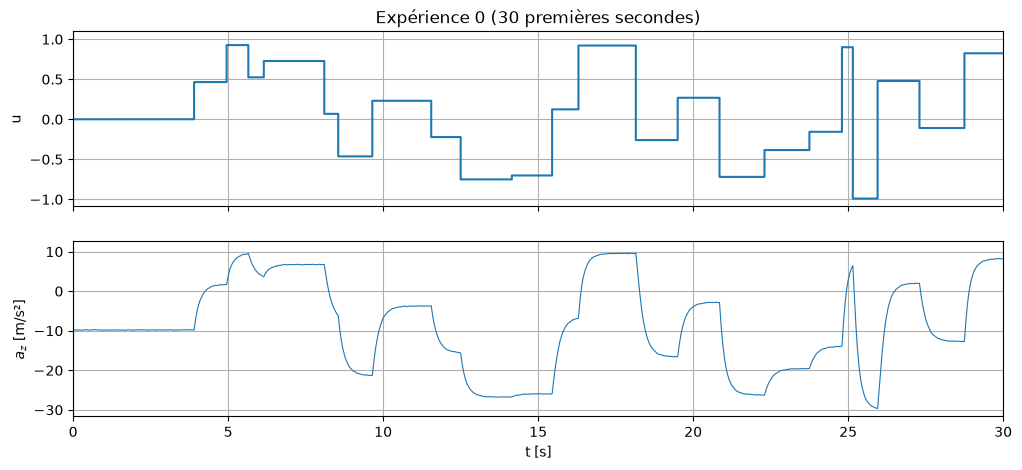

In [43]:
r = 0
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].step(t, U[r], where='post'); ax[0].set_ylabel('u'); ax[0].grid()
ax[1].plot(t, Y[r], lw=0.8); ax[1].set_ylabel('$a_z$ [m/s²]'); ax[1].set_xlabel('t [s]'); ax[1].grid()
ax[0].set_xlim(0, 30); ax[0].set_title(f'Expérience {r} (30 premières secondes)')
savefig('01_exemple_experience'); plt.show()

## 2. Le signal d'entrée u

u ∈ [-1.000, 1.000]
Début : u = 0 pendant les 40 premiers échantillons (2 s) dans toutes les expériences
Durée des paliers : 5 à 39 échantillons (0.25 à 1.95 s)


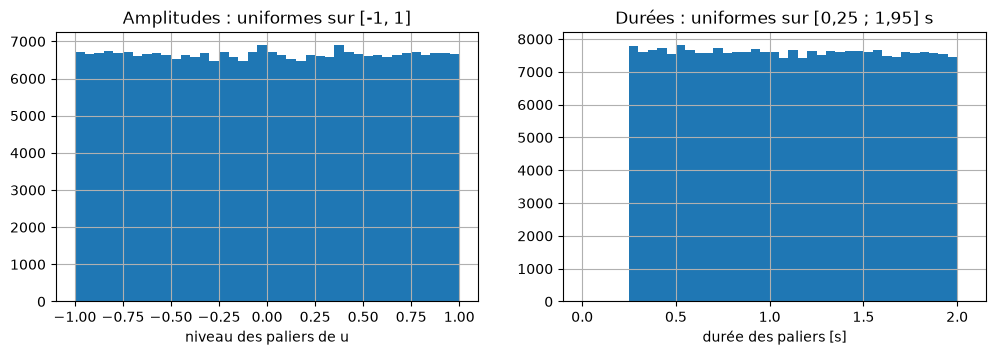

In [44]:
seg_len, levels = [], []
for u in U:
    ch = np.nonzero(np.diff(u))[0]
    seg_len += list(np.diff(ch)); levels += list(u[ch[1:] + 1])
seg_len, levels = np.array(seg_len), np.array(levels)
first_change = np.array([np.nonzero(np.diff(u))[0][0] for u in U])

print(f'u ∈ [{U.min():.3f}, {U.max():.3f}]')
print(f'Début : u = 0 pendant les {first_change.min()+1} premiers échantillons ({(first_change.min()+1)*Ts:.0f} s) dans toutes les expériences')
print(f'Durée des paliers : {seg_len.min()} à {seg_len.max()} échantillons ({seg_len.min()*Ts:.2f} à {seg_len.max()*Ts:.2f} s)')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(levels, bins=40); ax[0].set_xlabel('niveau des paliers de u'); ax[0].set_title('Amplitudes : uniformes sur [-1, 1]')
ax[1].hist(seg_len * Ts, bins=np.arange(0, 2.1, 0.05)); ax[1].set_xlabel('durée des paliers [s]'); ax[1].set_title('Durées : uniformes sur [0,25 ; 1,95] s')
for a in ax: a.grid()
savefig('02_signal_entree'); plt.show()

**Lecture :** u est un **APRBS** (paliers d'amplitude et de durée aléatoires). Les amplitudes couvrent uniformément [-1, 1] et les durées vont de 0,25 s (≈ temps de montée : on voit les transitoires) à 1,95 s (≈ 4 × tr5 % : on voit les régimes établis). C'est un bon signal d'excitation pour l'identification.

## 3. Contrôles de validité

Trois tests simples, expérience par expérience :
- **valeurs manquantes / infinies** ;
- **bornes physiques** : en simulation, az reste dans ≈ [-30, +11] m/s² ; on prend une marge large ([-40, 20]) ;
- **capteur figé** : la même valeur exacte répétée sur plusieurs échantillons consécutifs (impossible avec un bruit de mesure continu).

In [45]:
print('NaN / inf :', np.isnan(U).sum() + np.isnan(Y).sum(), np.isinf(U).sum() + np.isinf(Y).sum())

AZ_MIN, AZ_MAX = -40, 20
out_of_range = np.nonzero(((Y < AZ_MIN) | (Y > AZ_MAX)).any(1))[0]

def longest_constant_run(y):
    same = np.r_[False, np.diff(y) == 0]
    best = run = 0
    for s in same:
        run = run + 1 if s else 0; best = max(best, run)
    return best
frozen = np.array([r for r in range(n_exp) if longest_constant_run(Y[r]) >= 5])

print('Hors bornes physiques :', out_of_range.tolist())
print('Capteur figé (≥ 5 valeurs identiques) :', frozen.tolist())
BAD = sorted(int(r) for r in set(out_of_range) | set(frozen))
print('→ expériences rejetées :', BAD)

NaN / inf : 0 0
Hors bornes physiques : [122, 455, 1233, 1677]
Capteur figé (≥ 5 valeurs identiques) : [122, 1677]
→ expériences rejetées : [122, 455, 1233, 1677]


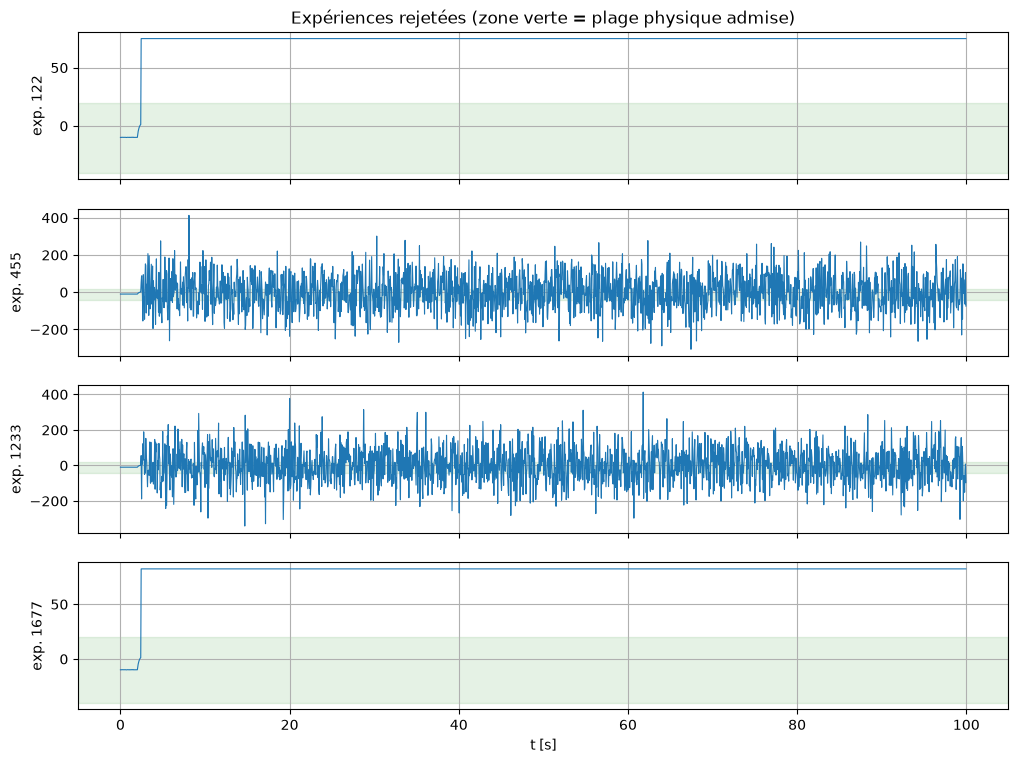

exp. 122: corrompue à partir de t = 2.45 s
exp. 455: corrompue à partir de t = 2.45 s
exp. 1233: corrompue à partir de t = 2.45 s
exp. 1677: corrompue à partir de t = 2.45 s


In [46]:
fig, axs = plt.subplots(len(BAD), 1, figsize=(12, 2.2 * len(BAD)), sharex=True)
for a, r in zip(axs, BAD):
    a.plot(t, Y[r], lw=0.8); a.set_ylabel(f'exp. {r}'); a.grid()
    a.axhspan(AZ_MIN, AZ_MAX, color='g', alpha=0.1)
axs[0].set_title('Expériences rejetées (zone verte = plage physique admise)'); axs[-1].set_xlabel('t [s]')
savefig('03_experiences_rejetees'); plt.show()
for r in BAD:
    print(f'exp. {r}: corrompue à partir de t = {np.argmax((Y[r] < AZ_MIN) | (Y[r] > AZ_MAX)) * Ts:.2f} s')

**Lecture :** 4 expériences sont inutilisables à partir de t ≈ 2,45 s :
- **122 et 1677** : capteur **figé** à une valeur constante (75 et 82,3 m/s²) ;
- **455 et 1233** : capteur **défaillant**, valeurs erratiques jusqu'à ±400 m/s².

Même le début (avant 2,45 s) de ces 4 expériences est suspect : les mêmes valeurs y apparaissent alors que les commandes diffèrent. On les **supprime entièrement** (perte : 4 / 3000 = 0,13 % des données).

## 4. Pics isolés : attention aux faux positifs

Méthode classique : comparer chaque point à la **médiane glissante** de ses voisins ; un point très éloigné serait un pic.
Problème : pendant un transitoire rapide (après un changement de palier), la courbe a une forte courbure et le filtre médian « coupe le virage » → de faux pics.

Points à plus de 1 m/s² de la médiane glissante : 22,402 dans 2980 expériences
dont 97.8 % à moins de 3 échantillons d'un changement de u


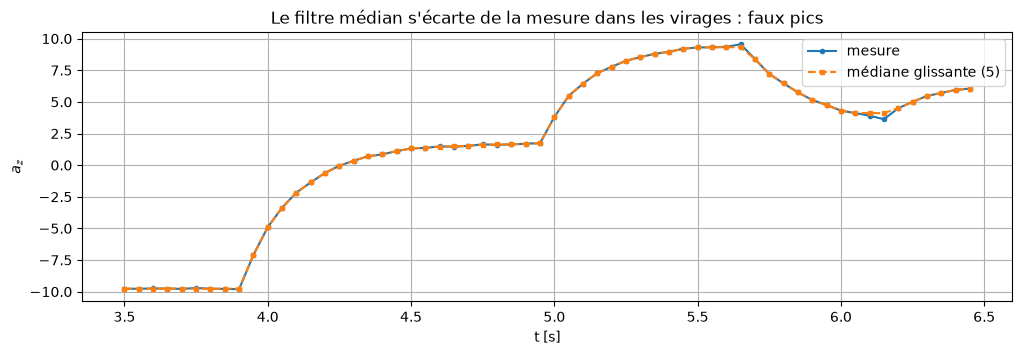

In [47]:
GOOD = np.setdiff1d(np.arange(n_exp), BAD)
Yg, Ug = Y[GOOD], U[GOOD]
R_med = Yg - np.stack([medfilt(y, 5) for y in Yg])
print(f'Points à plus de 1 m/s² de la médiane glissante : {(np.abs(R_med) > 1).sum():,} dans {np.unique(np.nonzero(np.abs(R_med) > 1)[0]).size} expériences')

# Où sont-ils ? Juste après les changements de commande ?
dist = []
for i, j in zip(*np.nonzero(np.abs(R_med) > 1)):
    ch = np.nonzero(np.diff(Ug[i]))[0] + 1
    dist.append(np.min(np.abs(j - ch)))
dist = np.array(dist)
print(f'dont {np.mean(dist <= 3)*100:.1f} % à moins de 3 échantillons d\'un changement de u')

r, k = 0, slice(70, 130)
plt.figure(figsize=(12, 3.5))
plt.plot(t[k], Yg[r, k], 'o-', ms=3, label='mesure')
plt.plot(t[k], medfilt(Yg[r], 5)[k], 's--', ms=3, label='médiane glissante (5)')
plt.grid(); plt.legend(); plt.xlabel('t [s]'); plt.ylabel('$a_z$')
plt.title('Le filtre médian s\'écarte de la mesure dans les virages : faux pics')
savefig('04_faux_pics_mediane'); plt.show()

**Conclusion :** ces « pics » sont presque tous collés à un changement de commande : ce sont des **faux positifs**. Pour détecter de vrais pics, il faut comparer la mesure à ce qu'un **modèle** du système prédit, pas à une médiane. On construit ce modèle simple dans les deux sections suivantes.

## 5. Caractéristique statique az = f(u)

À la fin de chaque palier assez long (≥ 0,75 s ≈ 1,7 × tr5 %), le système est en régime établi : on relève le couple (u, az).

Ajustement : az = 26.67·tanh(0.992·u) + (-9.81)
Écart-type des résidus : tanh 0.203  |  droite 0.916 m/s²
Vol stationnaire (az = 0) : u_hover ≈ 0.389


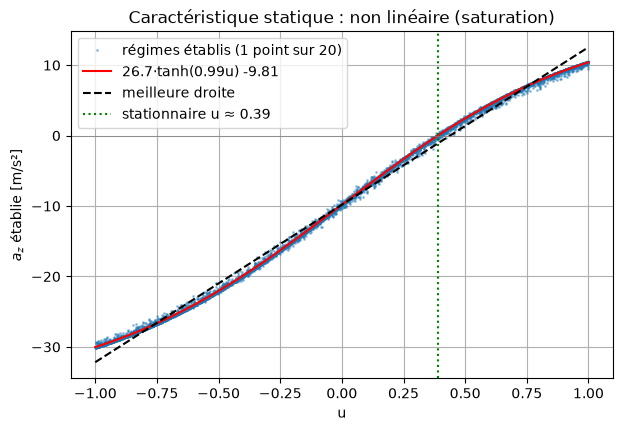

In [48]:
ss_u, ss_y = [], []
for u, y in zip(Ug, Yg):
    ends = np.r_[np.nonzero(np.diff(u))[0], N - 1]
    for e in ends:
        if e >= 15 and np.all(u[e-14:e+1] == u[e]):
            ss_u.append(u[e]); ss_y.append(np.median(y[e-3:e+1]))
ss_u, ss_y = np.array(ss_u), np.array(ss_y)

f_tanh = lambda u, A, B, c: A * np.tanh(c * u) + B
(A, B, c), _ = curve_fit(f_tanh, ss_u, ss_y, p0=[26, -9.8, 1])
lin = np.polyfit(ss_u, ss_y, 1)
u_hover = np.arctanh(-B / A) / c
print(f'Ajustement : az = {A:.2f}·tanh({c:.3f}·u) + ({B:.2f})')
print(f'Écart-type des résidus : tanh {np.std(ss_y - f_tanh(ss_u, A, B, c)):.3f}  |  droite {np.std(ss_y - np.polyval(lin, ss_u)):.3f} m/s²')
print(f'Vol stationnaire (az = 0) : u_hover ≈ {u_hover:.3f}')

uu = np.linspace(-1, 1, 200)
plt.figure(figsize=(7, 4.5))
plt.plot(ss_u[::20], ss_y[::20], '.', ms=2, alpha=0.4, label='régimes établis (1 point sur 20)')
plt.plot(uu, f_tanh(uu, A, B, c), 'r', label=f'{A:.1f}·tanh({c:.2f}u) {B:+.2f}')
plt.plot(uu, np.polyval(lin, uu), 'k--', label='meilleure droite')
plt.axhline(0, color='gray', lw=0.5); plt.axvline(u_hover, color='g', ls=':', label=f'stationnaire u ≈ {u_hover:.2f}')
plt.xlabel('u'); plt.ylabel('$a_z$ établie [m/s²]'); plt.grid(); plt.legend()
plt.title('Caractéristique statique : non linéaire (saturation)')
savefig('05_caracteristique_statique'); plt.show()

**Lecture :**
- La relation est **non linéaire** : saturation de type tanh (cohérent avec la saturation des moteurs). Un modèle linéaire fait une erreur ≈ 4,5 fois plus grande → c'est ce qui justifie le **réseau de neurones** demandé.
- Asymptotes : u = 0 → az = -9,81 (chute libre), u = 1 → ≈ +10,5, u = -1 → ≈ -30.
- **Vol stationnaire vers u ≈ 0,39** : point de fonctionnement central de la mission.

## 6. Bruit de mesure et recherche des vrais pics

**Idée :** un modèle « boîte grise » très simple, dit de **Wiener** : un premier ordre linéaire suivi de la non-linéarité statique trouvée ci-dessus :

$$x(k) = a\,x(k-1) + b\,u(k-1), \qquad a_z(k) = A\tanh(c\,x(k)) + B$$

On estime a et b par moindres carrés (en inversant la tanh), puis on **simule le modèle en boucle ouverte** sur u uniquement, sans jamais utiliser la mesure. Le résidu mesure − simulation contient alors : le bruit + les défauts du capteur + ce que le modèle n'explique pas.
Ce modèle sert ici d'**outil de contrôle des données** ; l'identification proprement dite (linéaire et réseau de neurones) est l'étape 3.

In [49]:
Xg = np.arctanh(np.clip((Yg - B) / A, -0.999, 0.999)) / c          # inversion de la non-linéarité
F = np.stack([Xg[:, :-1], Ug[:, :-1]], -1).reshape(-1, 2)
(a, b) = np.linalg.lstsq(F, Xg[:, 1:].ravel(), rcond=None)[0]
tau = -Ts / np.log(a)
print(f'a = {a:.4f}, b = {b:.4f}  (gain statique b/(1-a) = {b/(1-a):.3f})  →  constante de temps τ = {tau:.3f} s')

x = np.zeros_like(Ug)
for k in range(1, N):
    x[:, k] = a * x[:, k-1] + b * Ug[:, k-1]
Yhat = A * np.tanh(c * x) + B
E = Yg - Yhat
sigma = 1.4826 * np.median(np.abs(E - np.median(E)))     # écart-type robuste
print(f'Résidu : écart-type {E.std():.4f} m/s² (robuste {sigma:.4f}), max |résidu| = {np.abs(E).max():.3f} = {np.abs(E).max()/sigma:.1f} σ')
for kσ in (4, 5, 6):
    print(f'  points > {kσ}σ : {(np.abs(E) > kσ*sigma).sum()}')

a = 0.7787, b = 0.2231  (gain statique b/(1-a) = 1.008)  →  constante de temps τ = 0.200 s
Résidu : écart-type 0.0447 m/s² (robuste 0.0447), max |résidu| = 0.261 = 5.8 σ
  points > 4σ : 399
  points > 5σ : 3
  points > 6σ : 0


Attendu pour un bruit gaussien pur sur 5,992,000 points : >4σ ≈ 380, >5σ ≈ 3.4, >6σ ≈ 0.012


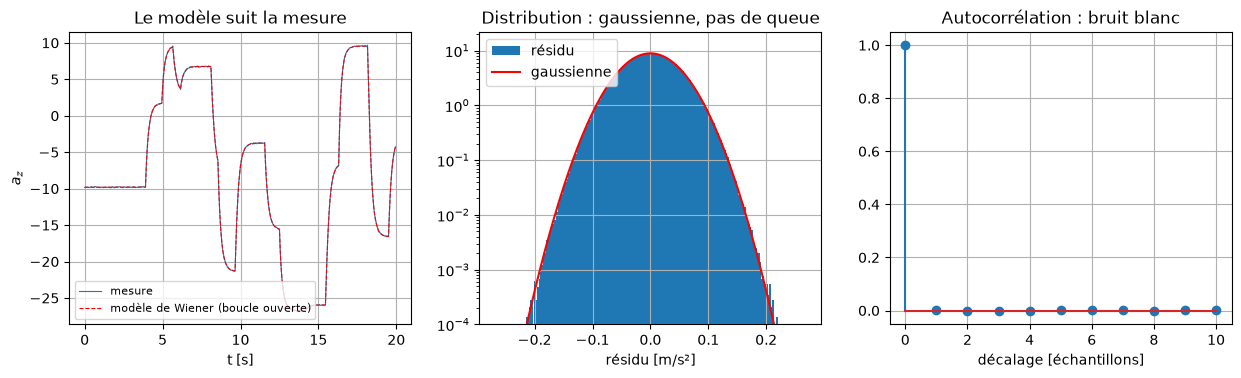

Biais par expérience : de -0.0025 à +0.0042 m/s² (négligeable)
Écart-type par expérience : de 0.0416 à 0.0472 m/s² (homogène)


In [50]:
from math import erfc, sqrt
n_pts = E.size
print(f'Attendu pour un bruit gaussien pur sur {n_pts:,} points : >4σ ≈ {n_pts*erfc(4/sqrt(2)):.0f}, >5σ ≈ {n_pts*erfc(5/sqrt(2)):.1f}, >6σ ≈ {n_pts*erfc(6/sqrt(2)):.3f}')

e = E.ravel()
lags = np.arange(0, 11)
ac = [1.0] + [np.mean([np.corrcoef(E[i, :-l], E[i, l:])[0, 1] for i in range(0, len(E), 30)]) for l in lags[1:]]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
r = 0; k = slice(0, 400)
ax[0].plot(t[k], Yg[r, k], lw=0.8, label='mesure'); ax[0].plot(t[k], Yhat[r, k], 'r--', lw=0.8, label='modèle de Wiener (boucle ouverte)')
ax[0].set_xlabel('t [s]'); ax[0].set_ylabel('$a_z$'); ax[0].legend(loc='lower left', fontsize=8); ax[0].set_title('Le modèle suit la mesure')
xs = np.linspace(-6, 6, 200) * sigma
ax[1].hist(e, bins=200, density=True, label='résidu'); ax[1].plot(xs, np.exp(-xs**2/(2*sigma**2))/(sigma*np.sqrt(2*np.pi)), 'r', label='gaussienne')
ax[1].set_yscale('log'); ax[1].set_ylim(1e-4, None); ax[1].set_xlabel('résidu [m/s²]'); ax[1].legend(); ax[1].set_title('Distribution : gaussienne, pas de queue')
ax[2].stem(lags, ac); ax[2].set_xlabel('décalage [échantillons]'); ax[2].set_title('Autocorrélation : bruit blanc')
for x_ in ax: x_.grid()
savefig('06_analyse_bruit'); plt.show()

print(f'Biais par expérience : de {E.mean(1).min():+.4f} à {E.mean(1).max():+.4f} m/s² (négligeable)')
print(f'Écart-type par expérience : de {E.std(1).min():.4f} à {E.std(1).max():.4f} m/s² (homogène)')

**Conclusions de la section 6**
- Le résidu est un **bruit blanc gaussien** d'écart-type ≈ 0,045 m/s², identique dans toutes les expériences (pas de biais, pas de dérive).
- Le nombre de points au-delà de 4-5 σ correspond à ce qu'on attend d'un bruit gaussien : **aucun pic aberrant** dans les 2996 expériences restantes. Les « ~400 pics » du premier examen (filtre médian) étaient des faux positifs.
- Bonus : un modèle à **4 paramètres** (a, b, A, B) explique déjà les données à la précision du bruit. C'est une **référence boîte grise** très utile pour l'étape 3 (le réseau de neurones devra faire au moins aussi bien), et la constante de temps trouvée (τ ≈ 0,2 s) est cohérente avec le choix Ts = 0,05 s.

## 7. Rejeu Simulink (optionnel — après `replay_data.m`)

`replay_data.m` rejoue les commandes de quelques expériences dans `UAV_model.slx`. Si la simulation sans bruit se superpose aux données, la sortie est bien az **et** les données proviennent du même drone que celui de l'évaluation finale.

exp.    0 : écart données - simulation = +0.001 ± 0.044 m/s²  (meilleur décalage 0 éch.)
exp.    1 : écart données - simulation = -0.000 ± 0.044 m/s²  (meilleur décalage 0 éch.)
exp.    2 : écart données - simulation = +0.002 ± 0.045 m/s²  (meilleur décalage 0 éch.)
exp.  500 : écart données - simulation = -0.001 ± 0.045 m/s²  (meilleur décalage 0 éch.)
exp. 1000 : écart données - simulation = +0.000 ± 0.045 m/s²  (meilleur décalage 0 éch.)
exp. 2000 : écart données - simulation = -0.000 ± 0.045 m/s²  (meilleur décalage 0 éch.)
exp. 2999 : écart données - simulation = -0.002 ± 0.045 m/s²  (meilleur décalage 0 éch.)
Bruit simulé avec g_noise = 0.01 : 0.0004 m/s²  |  bruit des données : 0.0447 m/s²


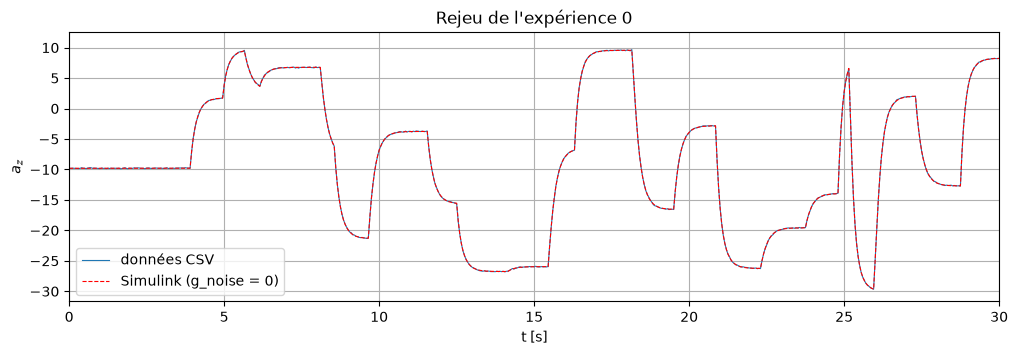

In [51]:
REPLAY_DIRS = [ROOT / 'matlab', ROOT / 'Matlab files', ROOT / 'results' / 'replay']
rep_dir = next((p for p in REPLAY_DIRS if (p / 'replay_az_g0.csv').exists()), None)
if rep_dir is None:
    print('Fichiers de rejeu introuvables. Lancer replay_data.m dans MATLAB, puis copier replay_az_g0.csv, replay_az_g001.csv et replay_rows.csv dans un de ces dossiers :')
    for p in REPLAY_DIRS: print('  ', p.resolve())
else:
    rows = np.atleast_1d(np.loadtxt(rep_dir / 'replay_rows.csv', delimiter=',')).astype(int)
    S0 = np.atleast_2d(np.loadtxt(rep_dir / 'replay_az_g0.csv', delimiter=','))
    S1 = np.atleast_2d(np.loadtxt(rep_dir / 'replay_az_g001.csv', delimiter=','))
    for i, r in enumerate(rows):
        best = min(range(-3, 4), key=lambda d: np.std(np.roll(S0[i], d)[5:-5] - Y[r, 5:-5]))
        e0 = Y[r] - S0[i]
        print(f'exp. {r:4d} : écart données - simulation = {e0[5:].mean():+.3f} ± {e0[5:].std():.3f} m/s²  (meilleur décalage {best} éch.)')
    print(f'Bruit simulé avec g_noise = 0.01 : {np.std(S1 - S0):.4f} m/s²  |  bruit des données : {sigma:.4f} m/s²')
    r = rows[0]
    plt.figure(figsize=(12, 3.5)); plt.plot(t, Y[r], lw=0.8, label='données CSV'); plt.plot(t, S0[0], 'r--', lw=0.8, label='Simulink (g_noise = 0)')
    plt.xlim(0, 30); plt.grid(); plt.legend(); plt.xlabel('t [s]'); plt.ylabel('$a_z$'); plt.title(f'Rejeu de l\'expérience {r}')
    savefig('07_rejeu_simulink'); plt.show()

## 8. Jeu de données final

- Suppression des 4 expériences corrompues → 2996 expériences.
- Découpage **par expériences entières** (jamais à l'intérieur d'une expérience), tirage aléatoire reproductible (graine 0) : 70 % entraînement, 15 % validation, 15 % test.
- Normalisation (moyenne 0, écart-type 1) calculée **uniquement sur l'entraînement**, puis appliquée partout. On sauvegarde les données **non normalisées** + les coefficients : chaque modèle normalise lui-même, ce qui évite de mélanger les échelles.

In [52]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(GOOD)
n_tr, n_va = int(0.70 * len(perm)), int(0.15 * len(perm))
idx = {'train': np.sort(perm[:n_tr]), 'val': np.sort(perm[n_tr:n_tr+n_va]), 'test': np.sort(perm[n_tr+n_va:])}
for k, v in idx.items(): print(f'{k:5s}: {len(v)} expériences')

norm = {'u_mean': U[idx['train']].mean(), 'u_std': U[idx['train']].std(),
        'az_mean': Y[idx['train']].mean(), 'az_std': Y[idx['train']].std()}
print({k: round(float(v), 4) for k, v in norm.items()})

np.savez_compressed(OUT_DIR / 'dataset_v1.npz',
    U_train=U[idx['train']].astype(np.float32), Y_train=Y[idx['train']].astype(np.float32),
    U_val=U[idx['val']].astype(np.float32),     Y_val=Y[idx['val']].astype(np.float32),
    U_test=U[idx['test']].astype(np.float32),   Y_test=Y[idx['test']].astype(np.float32),
    idx_train=idx['train'], idx_val=idx['val'], idx_test=idx['test'], rejected=np.array(BAD),
    Ts=Ts, **norm,
    wiener_a=a, wiener_b=b, static_A=A, static_B=B, static_c=c, noise_std=sigma)
print('Sauvegardé :', (OUT_DIR / 'dataset_v1.npz').resolve())

train: 2097 expériences
val  : 449 expériences
test : 450 expériences
{'u_mean': -0.0013, 'u_std': 0.5725, 'az_mean': -9.838, 'az_std': 11.9258}
Sauvegardé : C:\Users\ezabl\Documents\Edouard\CS_2A\EI_Data\EIVSCODE\ei-rl-quadrotor\data\processed\dataset_v1.npz


## Bilan (pour le rapport)

| Contrôle | Méthode | Résultat |
|---|---|---|
| Valeurs manquantes | NaN / inf | aucune |
| Bornes physiques | az ∈ [-40, 20] m/s² | 2 expériences hors bornes (455, 1233) |
| Capteur figé | ≥ 5 valeurs identiques consécutives | 2 expériences (122, 1677) |
| Pics isolés | résidu d'un modèle simulé en boucle ouverte | aucun (les détections par filtre médian sont des faux positifs) |
| Biais / dérive | moyenne et écart-type du résidu par expérience | aucun |
| Bruit | résidu | blanc, gaussien, σ ≈ 0,045 m/s² |

**Décision :** suppression de 4 expériences sur 3000, aucune correction point par point nécessaire.
**Enseignements pour la suite :** système non linéaire (saturation tanh) avec une dynamique de premier ordre (τ ≈ 0,2 s, retard d'un échantillon) ; vol stationnaire vers u ≈ 0,39.